# F1 Race Winner Prediction

## Project Overview

F1 Race Winner Prediction is a project focused on understanding and predicting Formula 1 race outcomes using data and machine learning.

Formula 1 is shaped by more than just speed. Qualifying performance, team strength, driver form, track characteristics, and conditions like weather all play a role in determining who is most likely to win a race. This project brings these elements together and uses them to calculate a **winning probability for each driver** before a Grand Prix.

Instead of selecting only one predicted winner, the model gives every driver a score. Drivers are then ranked based on this score, and the **Top 3 drivers with the highest chance of winning** are presented as the final prediction.


## Objective

The main goal of this project is to build a model that can estimate the **probability of winning** for each driver in a Formula 1 race.

The project focuses on:

* Bringing together data from different F1 sources into one usable dataset,
* Cleaning and selecting variables that are relevant for performance and strategy,
* Creating features from historical data instead of relying only on direct user input,
* Producing probability scores that can be used to rank drivers and identify the Top 3.

This notebook starts with preparing and cleaning the dataset so it can be used reliably for analysis and later model development.


## Central Research Question

**How can driver performance, team performance, qualifying results, track characteristics, and race context be used to estimate each driver’s probability of winning a Formula 1 Grand Prix?**


## Analytical Approach

This project is treated as a **binary classification problem with a ranking-based output**.

Instead of predicting a single race winner, the model classifies each driver into one of two performance groups based on historical race results:

* Good Performance (1) → Driver finishes inside the Top 10
* Worse Performance (0) → Driver finishes outside the Top 10 or does not finish

The model outputs a probability score that represents how likely a driver is to belong to the good performance group. These scores are then used to rank drivers within a race context, and the three highest-ranked drivers are assigned as the predicted podium (1st, 2nd, and 3rd).

The main machine learning method used is K-Nearest Neighbors (KNN). This model predicts performance by comparing each driver’s current race context to similar historical race situations and learning from how those situations ended. This makes the approach intuitive and explainable, as predictions are based on similarity rather than a fixed mathematical formula.


### Evaluation Metrics

The model will be evaluated using:

* **Top-3 Accuracy** (whether the real race winner appears in the predicted Top 3),
* **Probability Error** (how close the predicted chances are to what actually happens in the race),
* **Feature review** to understand which variables have the biggest impact on the predictions.

## Dataset Description

The dataset used in this project is based on data from the **F1DB repository**, which provides structured and publicly available Formula 1 data.

The raw data was originally separated into five main datasets:

* Race information
* Race results
* Qualifying results
* Driver standings
* Constructor standings

These datasets were later combined into a single dataset and filtered to include only the **last five seasons (2021–2025)** to keep the information relevant to the current racing environment.


## Methodology & Workflow

This project follows a simple, iterative workflow:

* **Planning** -> Define the research question and identify relevant F1 variables.
* **Preparation** -> Collect, merge, clean, and filter the dataset to the last five seasons.
* **Modeling** -> Train a ine model and improve it using CatBoost.
* **Evaluation** -> Compare results, interpret feature importance, and document limitations and future improvements.

This notebook focuses on the **Preparation** stage, especially dataset inspection and data cleaning.


## Notebook Goals

In this notebook, I will:

* Import and inspect the dataset.
* Convert time-based and numeric columns into consistent numeric formats.
* Create a binary performance label (good vs worse performance).
* Explore relationships between qualifying performance, drivers, teams, and race outcomes.
* Prepare the data for training a KNN classification model and probability-based ranking.


## Data Source and Data Cleaning Process

### Data Source

The data used in this project comes from the **F1DB open-source repository**, which provides structured and publicly available Formula 1 data. The repository contains information about races, drivers, constructors, qualifying results, and championship standings across multiple seasons.

I chose this source because it offers consistent formatting across years and includes all the main variables needed to understand race outcomes, such as driver performance, team performance, and qualifying results. This makes it suitable for both analysis and machine learning applications.


### Data Preparation and Cleaning Process

The original data covers Formula 1 seasons from **1950 up to the present**. To make the dataset more relevant for this project and easier to work with, I followed a step-by-step cleaning and selection process.

#### Step 1 – Dataset Separation

I first separated the data into **five main datasets**, each focusing on a different part of the racing domain: race information, race results, qualifying results, driver standings, and constructor standings. This helped me better understand what kind of information each dataset contained and how they could later be combined.

#### Step 2 – Dataset Combination

After that, I combined all five datasets into **one large dataset**. This allowed me to connect race-level information with driver and team performance in a single table. At this stage, the dataset contained **75 columns**, many of which were repeated or overlapping because the same type of information appeared in more than one source.

#### Step 3 – Time Filtering

To keep the data relevant to the current Formula 1 environment, I reduced the dataset to only include the **last five seasons (2021–2025)**. This way, the model focuses on modern racing conditions, current regulations, and recent performance trends instead of older historical patterns that may no longer apply.

#### Step 4 – Cleaning and Reducing Columns

Once the dataset was combined, I started cleaning it by:

* Removing repeated columns that represented the same information,
* Merging overlapping columns into a single version,
* Removing technical and source-related columns that were not useful for analysis or prediction.

This step helped reduce the complexity of the dataset and made it easier to work with.

#### Step 5 – Relevance-Based Selection

Finally, I removed columns that did not contribute directly to performance, strategy, or competitive context. This included variables with little analytical value and columns that contained mostly missing values.


### Final Dataset Overview

The final dataset represents a **cleaned and unified view of Formula 1 race data** from the last five seasons. Each row describes a driver’s participation in a specific race and includes information about:

* Driver and team identity,
* Race results and performance,
* Qualifying outcomes,
* Championship and team context.

In addition to the main variables used for the first version of the model, I also kept a small number of extra features. These are not used right away, but they allow room for **future improvements and feature engineering**, such as adding more detailed strategy or historical performance data later in the project.

## Dataset Loading and Initial Inspection

To begin working with the cleaned and combined dataset, I first load it into the notebook and take a quick look at its basic structure. This step helps confirm that the data has been imported correctly and provides an initial overview of its size, column structure, and general content before moving into more detailed analysis and feature engineering.

In the next cell, I display the dataset’s shape, preview the first few rows, and check for missing values to ensure the data is ready for further processing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
# Find the repository from either its root or notebooks/ folder.
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
file_path = ROOT / 'data' / 'processed/f1_combined_2021_2025_final.csv'
df = pd.read_csv(file_path)

# Display basic information
print("Dataset shape:", df.shape)
print("\nFirst 5 rows of the dataset:")
display(df.head())

# Check for missing values
print("\nChecking for missing (null) values in each column:")
display(df.isnull().sum())

Dataset shape: (2260, 17)

First 5 rows of the dataset:


,constructorId,driverId,engineManufacturerId,gap,grand,laps,points,position,reasonRetired,time,timePenalty,courseLength,date,turns,q1,q2,q3
0,mercedes,lewis-hamilton,mercedes,0.388,bahrain,56.0,25.0,1,NaN,1:32:03.897,NaN,5.412,2021-03-28,15,1:30.617,1:30.085,1:29.385
1,red-bull,max-verstappen,honda,+0.745,bahrain,56.0,18.0,2,NaN,1:32:04.642,NaN,5.412,2021-03-28,15,1:30.499,1:30.318,1:28.997
2,mercedes,valtteri-bottas,mercedes,+37.383,bahrain,56.0,16.0,3,NaN,1:32:41.280,NaN,5.412,2021-03-28,15,1:31.200,1:30.186,1:29.586
3,mclaren,lando-norris,mercedes,+46.466,bahrain,56.0,12.0,4,NaN,1:32:50.363,NaN,5.412,2021-03-28,15,1:30.902,1:30.099,1:29.974
4,red-bull,sergio-perez,honda,+52.047,bahrain,56.0,10.0,5,NaN,1:32:55.944,NaN,5.412,2021-03-28,15,1:31.165,1:30.659,NaN



Checking for missing (null) values in each column:


constructorId              0
driverId                   0
engineManufacturerId       0
gap                      269
grand                      0
laps                       0
points                     0
position                   0
reasonRetired           1960
time                     490
timePenalty             2138
courseLength               0
date                       0
turns                      0
q1                        29
q2                       588
q3                      1155
dtype: int64

## Data Types and Missing Value Handling

After loading and inspecting the dataset, the next step is to understand the structure of each column and how the data is represented. This includes checking the data types, identifying which variables are numerical or categorical, and confirming that the values are stored in a format that makes sense for analysis and modeling.

At the same time, I check for missing or incomplete values. Even a small number of null entries can affect feature engineering and model training, especially when working with probability-based predictions.

In the following cell, I review the dataset’s data types, identify any columns with missing values, and apply simple strategies to handle them. For categorical variables, missing values are replaced with a clear placeholder. For numerical variables, missing values are filled using summary statistics so that the overall distribution of the data remains stable.

In [2]:
# Display summary statistics and data types
print("Data types and non-null counts:\n")
display(df.info())

# Identify columns with missing data
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]
print("\nColumns with missing values:\n")
display(missing_values)

# Fill missing values for categorical columns
for col in df.select_dtypes(include='object').columns:
	df[col] = df[col].fillna('Unknown')

# Fill missing values for numeric columns
for col in df.select_dtypes(include=['float64', 'int64']).columns:
	df[col] = df[col].fillna(df[col].mean())


print("\nMissing values handled successfully!")


# Confirm there are no more null values
print("\nRechecking for missing values:")
display(df.isnull().sum())

Data types and non-null counts:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260 entries, 0 to 2259
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorId         2260 non-null   object 
 1   driverId              2260 non-null   object 
 2   engineManufacturerId  2260 non-null   object 
 3   gap                   1991 non-null   object 
 4   grand                 2260 non-null   object 
 5   laps                  2260 non-null   float64
 6   points                2260 non-null   float64
 7   position              2260 non-null   object 
 8   reasonRetired         300 non-null    object 
 9   time                  1770 non-null   object 
 10  timePenalty           122 non-null    float64
 11  courseLength          2260 non-null   float64
 12  date                  2260 non-null   object 
 13  turns                 2260 non-null   int64  
 14  q1                    2231 non-null   o

None


Columns with missing values:



gap               269
reasonRetired    1960
time              490
timePenalty      2138
q1                 29
q2                588
q3               1155
dtype: int64


Missing values handled successfully!

Rechecking for missing values:


constructorId           0
driverId                0
engineManufacturerId    0
gap                     0
grand                   0
laps                    0
points                  0
position                0
reasonRetired           0
time                    0
timePenalty             0
courseLength            0
date                    0
turns                   0
q1                      0
q2                      0
q3                      0
dtype: int64

## Data Types and Missing Value Handling

After loading the dataset, the next step is to check how each column is structured and what type of values it contains. This helps identify which variables can be used directly for analysis and which ones need to be converted into a numerical format.

At the same time, I look for missing or incomplete values. Even a small number of null entries can affect later steps, especially when working with similarity-based models.

In the following step, key performance columns are converted from text to numerical values so they can be compared and used in calculations. Qualifying times are handled separately and transformed into total seconds to keep all lap times on the same scale.

For missing values, categorical variables are replaced with a clear placeholder, while numerical variables are filled using simple summary values to keep the dataset stable and usable for further analysis and modeling.

In [3]:
cols = ["gap", "points", "position", "time", "turns"]

# Convert these columns to numeric (NOT q1, q2, q3 - those need special handling)
for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

int_cols = ["points", "position", "turns"]

for col in int_cols:
    df[col] = df[col].fillna(0).astype("int64")

# Handle qualifying times - convert from "M:SS.mmm" format to seconds
def time_to_seconds(x):
    """Convert M:SS.mmm format to total seconds"""
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "" or s.upper() in {"DNF", "DNS", "DSQ", "NC"}:
        return np.nan
    
    if ":" in s:
        parts = s.split(":")
        try:
            minutes = float(parts[0])
            seconds = float(parts[1])
            return minutes * 60 + seconds
        except:
            return np.nan
    
    try:
        return float(s)
    except:
        return np.nan

# Convert qualifying columns properly
for col in ["q1", "q2", "q3"]:
    df[col] = df[col].apply(time_to_seconds)

df[["gap", "points", "position", "time", "turns", "q1", "q2", "q3"]].dtypes


Out[1]: 
gap         float64
points        int64
position      int64
time        float64
turns         int64
q1          float64
q2          float64
q3          float64
dtype: object


## Creating the Performance Label (Good vs Worse)

Before training the model, I create a binary label that represents whether a driver had a strong race result.

For this project:
* **Good performance (1)** means the driver finished **inside the Top 10**.  
* **Worse performance (0)** means the driver finished **outside the Top 10** or did not have a classified finishing position.

This label will be the target variable for the KNN classification model.


In [4]:
# Convert finishing position to numeric where possible (DNF/DSQ/etc. become NaN)
df["position_num"] = pd.to_numeric(df["position"], errors="coerce")

# Binary label: Top 10 = good performance
df["good_performance"] = (df["position_num"] <= 10).astype(int)

# Quick check
print(df["good_performance"].value_counts())
display(df[["position", "position_num", "good_performance"]].head(10))


good_performance
1    1400
0     860
Name: count, dtype: int64


,position,position_num,good_performance
0,1,1,1
1,2,2,1
2,3,3,1
3,4,4,1
4,5,5,1
5,6,6,1
6,7,7,1
7,8,8,1
8,9,9,1
9,10,10,1


## Exploratory Data Analysis (EDA)

With the dataset cleaned and structured, the next step is to explore the data to understand its main patterns, distributions, and relationships.

The goal of this section is not to build the model yet, but to answer practical questions such as:
* How are finishing positions and points distributed across drivers and teams?
* How strong is the relationship between qualifying position and race outcome?
* Are certain drivers or teams consistently dominant at specific tracks?
* Do some tracks produce more unpredictable results than others?

By answering these questions, this analysis helps guide which variables and feature engineering strategies are most meaningful for the prediction model.

### Driver Performance Across Different Teams (Average Finishing Position)

One of the main assumptions in Formula 1 is that race performance is influenced not only by the **driver**, but also by the **team** and the **car they are driving**. This analysis explores how different driver - constructor combinations relate to finishing positions.

The goal is to identify:
* Which teams/driver consistently achieve better finishing positions on average
* How points are distributed across different teams
* The overall spread and variability of team performance
* How team strength correlates with race outcomes

In the following cells, I analyze team-level statistics including average finishing positions, total points, the distribution of results and track-based differation.

## Driver–Constructor Pairs by Top-3 Consistency

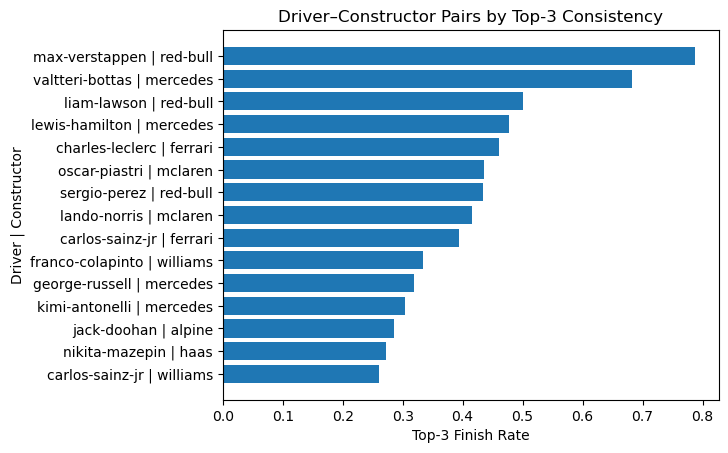

In [5]:
import matplotlib.pyplot as plt

# Create Top-3 indicator
df["top3"] = df["position"] <= 3

top3_rate = (
    df.groupby(["driverId", "constructorId"])["top3"]
    .mean()
    .reset_index()
    .sort_values("top3", ascending=False)
    .head(15)
)

plt.figure()
plt.barh(
    top3_rate["driverId"].astype(str) + " | " + top3_rate["constructorId"].astype(str),
    top3_rate["top3"]
)

plt.xlabel("Top-3 Finish Rate")
plt.ylabel("Driver | Constructor")
plt.title("Driver–Constructor Pairs by Top-3 Consistency")
plt.gca().invert_yaxis()
plt.show()


#### Interpretation and Conclusion

This visualization reveals which **driver–constructor combinations have the highest consistency in finishing in the Top 3**. The chart ranks the top 15 pairs by their Top-3 finish rate, showing drivers who regularly achieve podium positions (positions 1-3) with specific teams.

The data demonstrates that certain partnerships are far more successful at achieving Top-3 finishes than others. Drivers paired with competitive constructors like **Red Bull, Ferrari, and Mercedes** show significantly higher Top-3 rates compared to drivers with less competitive teams, illustrating the dramatic impact of car quality on achieving podium positions.

This visualization supports the idea that driver–constructor partnership is crucial for achieving consistent strong results and should be included as an important feature in the prediction model.

## Average Finishing Position by Constructor


Team Statistics (sorted by average finishing position):


,Avg Position,Median Position,Races,Total Points,Avg Points,Top-10 Rate
constructorId,,,,,,
red-bull,4.38,2.0,226,6603,29.22,0.88
ferrari,4.60,4.0,226,6494,28.73,0.94
mercedes,4.79,4.0,226,6182,27.35,0.92
mclaren,6.15,5.0,226,5693,25.19,0.82
aston-martin,9.34,10.0,226,3794,16.79,0.56
alpine,9.43,10.0,226,2534,11.21,0.58
racing-bulls,9.65,10.5,46,561,12.20,0.50
alphatauri,10.05,11.0,132,1267,9.60,0.45
williams,10.50,12.0,225,1701,7.56,0.40


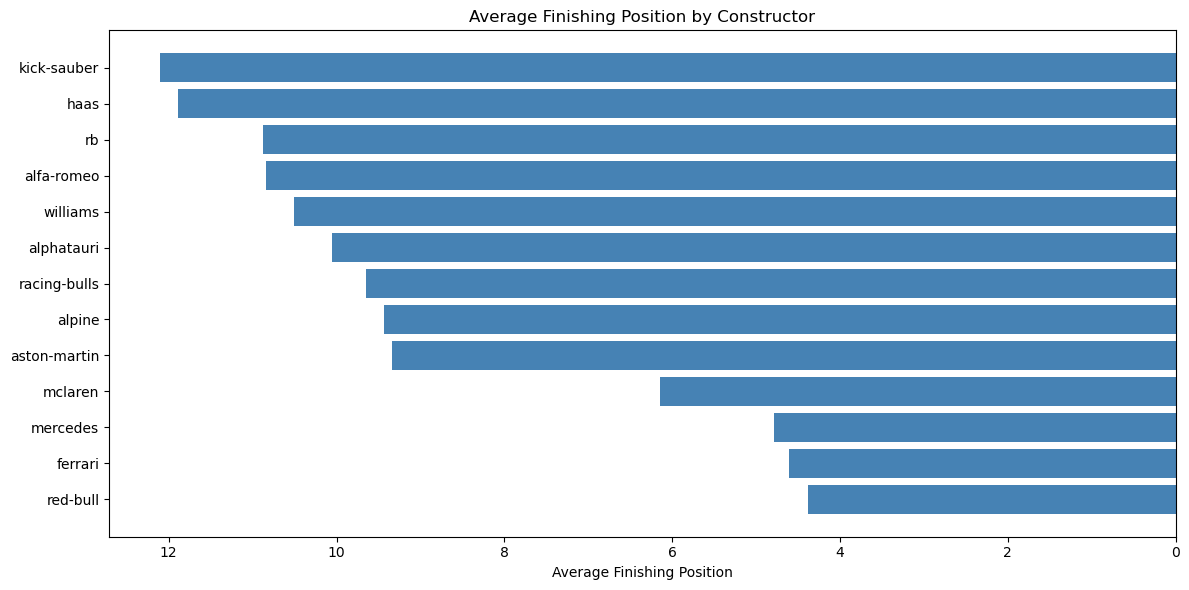

In [6]:
# Average finishing position by constructor
team_stats = df[df["position"].notna()].groupby("constructorId").agg({
    "position_num": ["mean", "median", "count"],
    "points": ["sum", "mean"],
    "good_performance": "mean"
}).round(2)

team_stats.columns = ["Avg Position", "Median Position", "Races", "Total Points", "Avg Points", "Top-10 Rate"]
team_stats = team_stats.sort_values("Avg Position")

print("\nTeam Statistics (sorted by average finishing position):")
display(team_stats.head(15))

# Average finishing position by team
fig, ax = plt.subplots(figsize=(12, 6))
team_avg_pos = df[df["position"].notna()].groupby("constructorId")["position_num"].mean().sort_values()
ax.barh(team_avg_pos.index, team_avg_pos.values, color='steelblue')
ax.set_xlabel("Average Finishing Position")
ax.set_title("Average Finishing Position by Constructor")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

### Interpretation and Conclusion

This visualization demonstrates the **average finishing position for each constructor across all races in 2021-2025**. It clearly shows a hierarchical structure in Formula 1 performance, where elite constructors achieve significantly better average positions than mid-field and lower-tier teams.

The chart reveals that teams like **Red Bull, Ferrari, and Mercedes** consistently finish in positions closer to the front (lower numbers on the scale), while constructors such as **Alpina, Haas, and Kick Sauber** average much further back in the field. This substantial difference in average finishing position reflects the significant impact of car performance and team resources on race outcomes.

Overall, this supports the idea that constructor strength plays an important role in driver performance and should be included as a key feature in the prediction model.

## Total Championship Points by Constructor

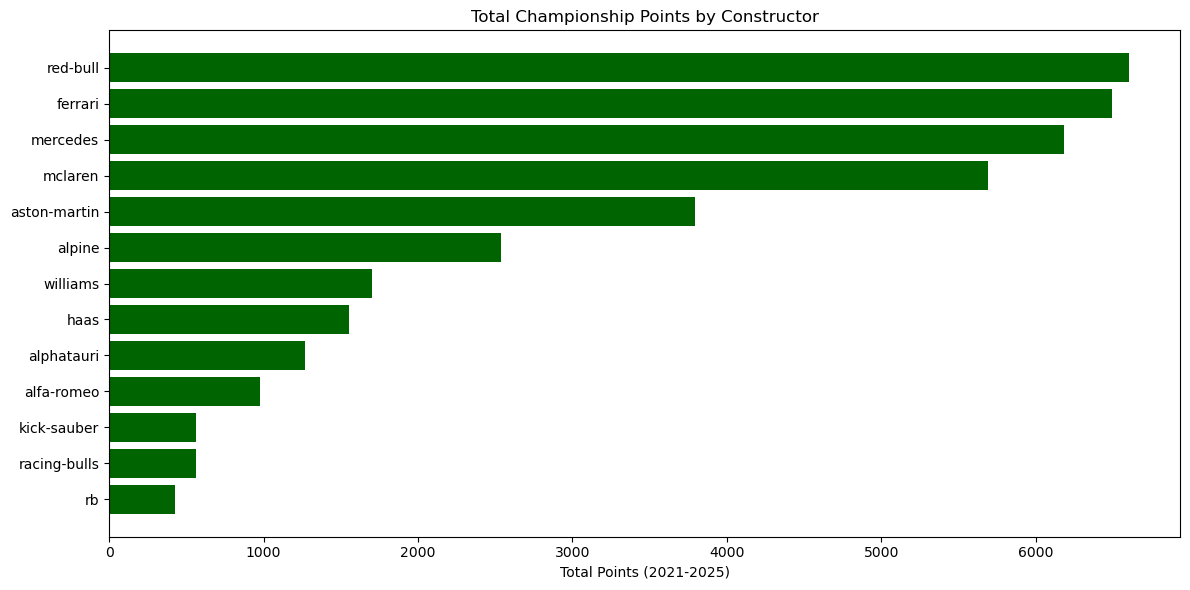

In [7]:
# Total points by team
fig, ax = plt.subplots(figsize=(12, 6))
team_points = df.groupby("constructorId")["points"].sum().sort_values(ascending=True)
ax.barh(team_points.index, team_points.values, color='darkgreen')
ax.set_xlabel("Total Points (2021-2025)")
ax.set_title("Total Championship Points by Constructor")
plt.tight_layout()
plt.show()

### Interpretation and Conclusion

This visualization shows the **total championship points accumulated by each constructor from 2021 to 2025**. It starkly illustrates the concentration of success in Formula 1, where a small group of elite constructors dominates the points standings.

**Red Bull, Ferrari, and Mercedes** clearly accumulate the vast majority of championship points, reflecting their sustained competitive advantage over the five-year period. In contrast, smaller teams with limited resources accumulate significantly fewer points, highlighting the resource-intensive nature of competitive Formula 1 racing.

This significant disparity in total points demonstrates that constructor strength and resources directly translate to consistent race success and championship competitiveness. Overall, this supports the idea that constructor performance is a critical predictor in the model and should be weighted as an important feature.

## Qualifying Performance vs Average Finishing Position

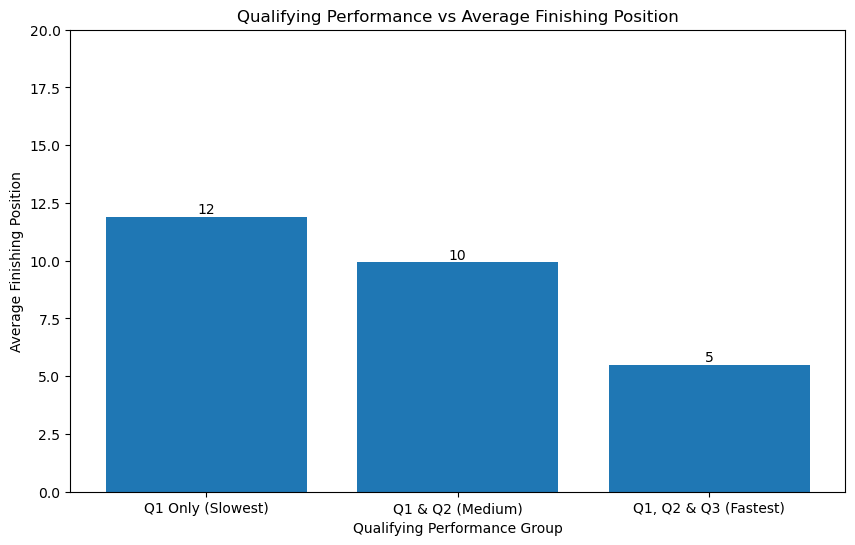

In [8]:
import numpy as np

# For race position, convert position to numeric (DNF/DNS/DSQ become NaN, then fill with 20)
df["race_position"] = pd.to_numeric(df["position"], errors="coerce")
df["race_position"] = df["race_position"].fillna(20)

# Create groups based on qualifying progression
df["qual_group"] = "Not Qualified"

# Group 1: Only Q1 (eliminated in Q1) - Slowest
has_q1_only = df["q1"].notna() & df["q2"].isna()
df.loc[has_q1_only, "qual_group"] = "Q1 Only (Slowest)"

# Group 2: Q1 and Q2 (eliminated in Q2) - Medium  
has_q1_q2 = df["q1"].notna() & df["q2"].notna() & df["q3"].isna()
df.loc[has_q1_q2, "qual_group"] = "Q1 & Q2 (Medium)"

# Group 3: All Q1, Q2, Q3 (made it through all sessions) - Fastest
has_q1_q2_q3 = df["q1"].notna() & df["q2"].notna() & df["q3"].notna()
df.loc[has_q1_q2_q3, "qual_group"] = "Q1, Q2 & Q3 (Fastest)"

# Filter to only groups with results
qual_data = df[df["qual_group"] != "Not Qualified"].copy()

# Create average positions
avg_position = pd.DataFrame({
    "qual_group": [
        "Q1 Only (Slowest)",
        "Q1 & Q2 (Medium)",
        "Q1, Q2 & Q3 (Fastest)"
    ],
    "position_num": [
        qual_data[qual_data["qual_group"] == "Q1 Only (Slowest)"]["race_position"].mean(),
        qual_data[qual_data["qual_group"] == "Q1 & Q2 (Medium)"]["race_position"].mean(),
        qual_data[qual_data["qual_group"] == "Q1, Q2 & Q3 (Fastest)"]["race_position"].mean()
    ]
})

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(avg_position["qual_group"], avg_position["position_num"])
ax.set_xlabel("Qualifying Performance Group")
ax.set_ylabel("Average Finishing Position")
ax.set_title("Qualifying Performance vs Average Finishing Position")
ax.set_ylim(0, 20)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{round(height)}',
            ha='center', va='bottom')

plt.show()




### Interpretation and Conclusion

This visualization shows a clear relationship between qualifying performance and race results. Drivers who reach **Q3** tend to finish much closer to the front on average, while those eliminated in **Q1** generally finish further back.

Overall, this supports the idea that **qualifying performance is a strong indicator of race outcome** and should be included as a key feature in the prediction model when ranking drivers by their probability of strong performance.

## Track Differentiation: Average Position & Variability


Track Differentiation Statistics (Top 10 by Variability):


,grand,avg_position,std_position,min_position,max_position,range
10,france,8.6500,5.933607,0,20,20
12,hungary,8.5200,5.927985,0,20,20
20,portugal,9.5000,5.916080,0,19,19
28,turkey,10.5000,5.916080,1,20,19
22,russia,9.5000,5.916080,0,19,19
25,singapore,8.0125,5.862331,0,20,20
1,abu-dhabi,8.4125,5.849794,0,20,20
27,styria,8.5500,5.835238,0,18,18
17,miami,8.6125,5.832024,0,20,20
6,belgium,9.3300,5.827582,0,20,20


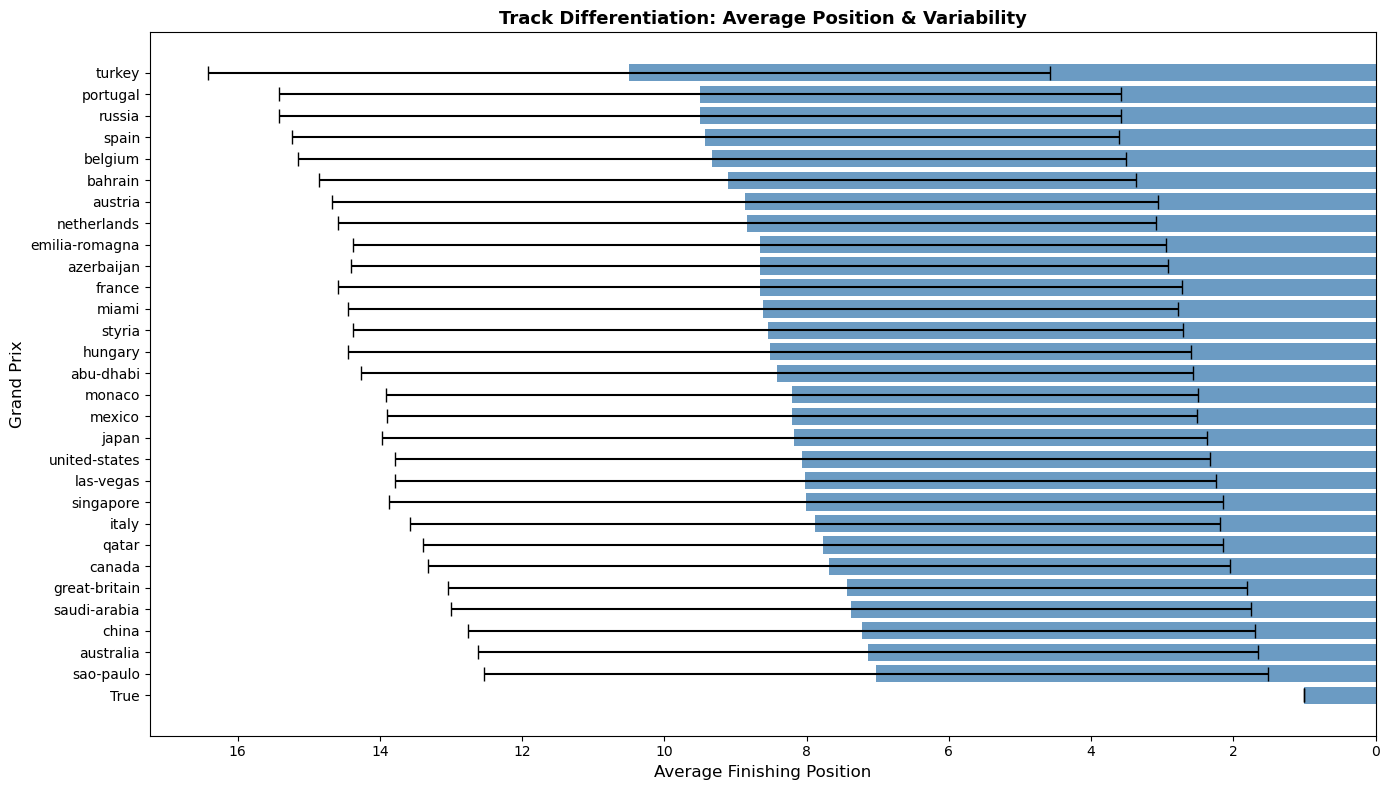

In [9]:
# Analyze track differentiation in positioning
track_stats = df.dropna(subset=["grand", "position_num"]).groupby("grand")["position_num"].agg([
    ('avg_position', 'mean'),
    ('std_position', 'std'),
    ('min_position', 'min'),
    ('max_position', 'max'),
    ('range', lambda x: x.max() - x.min())
]).reset_index().sort_values('std_position', ascending=False).head(10)

print("\nTrack Differentiation Statistics (Top 10 by Variability):")
display(track_stats)

# Create visualization showing average position with variability
fig, ax = plt.subplots(figsize=(14, 8))
track_avg = df.dropna(subset=["grand", "position_num"]).groupby("grand")["position_num"].mean().sort_values()
track_std = df.dropna(subset=["grand", "position_num"]).groupby("grand")["position_num"].std().loc[track_avg.index]

ax.barh(track_avg.index, track_avg.values, xerr=track_std.values, color='steelblue', capsize=5, alpha=0.8)
ax.set_xlabel("Average Finishing Position", fontsize=12)
ax.set_ylabel("Grand Prix", fontsize=12)
ax.set_title("Track Differentiation: Average Position & Variability", fontsize=13, fontweight='bold')
ax.invert_xaxis()

plt.tight_layout()
plt.show()


### Interpretation and Conclusion

This visualization compares tracks based on both average finishing position and how much results vary across races. Some circuits show tighter ranges and lower average positions, suggesting more stable and predictable race outcomes, while others display wider spreads, indicating greater variation in where drivers tend to finish.

For example, tracks such as **Monaco and Great Britain** tend to show tighter ranges of finishing positions, suggesting more predictable outcomes, while circuits like **Azerbaijan and Mexico** display wider spreads, indicating greater variation in race results.

Overall, this supports the idea that **track characteristics influence both performance level and result consistency**, making track identity an important feature for ranking drivers and estimating race outcomes.

## Correlation Matrix

This step explores how numerical features relate to each other and to race performance. The goal is to check whether some variables move together and to identify which features show a stronger relationship with finishing position and performance.

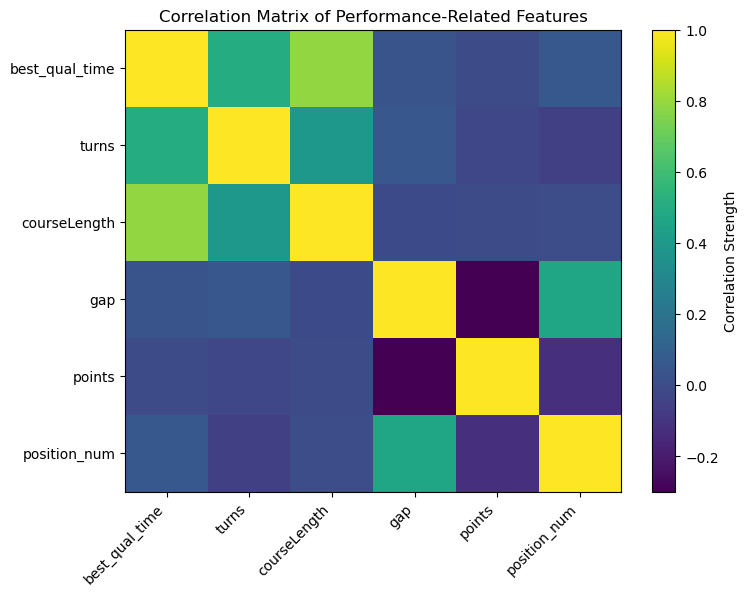

In [10]:
# Create best_qual_time as the minimum (fastest) of q1, q2, q3
df["best_qual_time"] = df[["q1", "q2", "q3"]].min(axis=1)

# Select only numerical columns relevant to performance
corr_cols = [
    "best_qual_time",
    "turns",
    "courseLength",
    "gap",
    "points",
    "position_num"
]

# Keep valid rows
corr_df = df[corr_cols].dropna()

# Compute correlation matrix
corr_matrix = corr_df.corr()

# Plot
plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Correlation Strength")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation Matrix of Performance-Related Features")
plt.show()


### Interpretation and Conclusion

This correlation matrix shows how different numerical features relate to each other and to race performance. **Qualifying time and finishing position** display a clearer relationship compared to track layout features such as turns and course length, which show weaker connections to final results.

The strong relationship between **gap and finishing position** highlights how closely race pace is tied to where a driver ends up in the classification. Overall, this suggests that **qualifying performance and race pace are more useful for prediction than track layout alone**.

## EDA Conclusion

The exploratory analysis shows clear performance patterns across constructors, qualifying stages, and track behavior. The constructor-based visualizations demonstrate that teams such as **Red Bull, Ferrari, and Mercedes** consistently appear closer to the front of the field, while others tend to finish further back, highlighting the impact of car performance and team context.

The qualifying analysis confirms a strong link between session progress and race outcome, where drivers reaching **Q3** finish significantly higher on average than those eliminated in **Q1 or Q2**. This supports the use of qualifying time as a key pre-race indicator in the model.

Track variability analysis shows that some circuits produce **more stable finishing patterns**, while others show wider spreads in results, suggesting that race predictability depends on track characteristics. The correlation matrix further supports these findings by showing stronger relationships between **qualifying time, gap, and finishing position** than between static track layout features such as turns and course length.

Together, these results justify the selection of **driver identity, constructor context, qualifying performance, and track identity** as core features for the KNN model and provide a clear data-driven basis for probability-based ranking and Top 3 predictions.

## Modeling Approach

The goal of this stage is to estimate how likely each driver is to deliver a strong race result based on their **pre-race context and how similar their situation is to past races**. Instead of trying to predict a single winner, the model gives every driver a score and uses that score to rank them within the same race.

To stay consistent with what I observed during the exploratory analysis, the model focuses on features that showed clear connections to performance, such as:

* **Driver and constructor context**, which reflect longer-term differences in team strength and car performance.
* **Qualifying performance**, which consistently relates to where drivers tend to finish in the race.
* **Track identity and characteristics**, which influence how stable or unpredictable race outcomes are.

The model produces a **binary performance label** (good vs worse) along with a **probability score**. This score is then used to rank drivers and select the predicted Top 3 for each race.


### Why This Approach

I chose **K-Nearest Neighbors (KNN)** because it fits naturally with the idea of learning from **similar past race situations**, rather than relying on a fixed formula or a black-box prediction.

For each driver, the model looks at past races with similar conditions - such as the same type of track, a similar team setup, and comparable qualifying performance. If those past situations often led to strong results, the driver receives a higher score. If they usually led to weaker results, the score is lower.

This approach feels intuitive and practical, because:

* **It is explainable** -> Each prediction can be linked back to comparable historical races.
* **It is flexible** -> New race data can be added without redesigning the model.
* **It reflects the EDA findings** -> It directly uses the same performance patterns observed in constructor strength, qualifying results, and track behavior.

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Features and target
features = [
"driverId",
"constructorId",
"engineManufacturerId",
"grand",
"turns",
"courseLength",
"q3"
]

# Column types
categorical_cols = ["driverId", "constructorId", "engineManufacturerId", "grand"]
numeric_cols = ["turns", "courseLength", "q3"]

# Fill missing values before creating model_df
model_df = df[features + ["good_performance", "date", "position_num"]].copy()

# Fill missing engineManufacturerId with 'Unknown'
model_df['engineManufacturerId'] = model_df['engineManufacturerId'].fillna('Unknown')

# Fill missing q3 with median (only if there are valid values)
if model_df['q3'].notna().sum() > 0:
	model_df['q3'] = model_df['q3'].fillna(model_df['q3'].median())
else:
	print("Warning: q3 has no valid values")
	model_df = model_df.drop('q3', axis=1)
	features.remove('q3')
	numeric_cols.remove('q3')

# Remove any remaining rows with NaN values
model_df = model_df.dropna()

# Check if we have enough data
if len(model_df) == 0:
	print("Error: No valid data after removing NaN values")
	print("Missing values per column:")
	print(df[features + ["good_performance"]].isnull().sum())
else:
	print(f"Dataset size: {len(model_df)} rows")


X = model_df[features]
y = model_df["good_performance"]


# Preprocessing
preprocessor = ColumnTransformer(
transformers=[
("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
("num", StandardScaler(), numeric_cols)
]
)


# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y
)

# Model
knn_model = Pipeline(steps=[
("preprocess", preprocessor),
("knn", KNeighborsClassifier(n_neighbors=15))
])


# Train
knn_model.fit(X_train, y_train)


# Accuracy
y_pred = knn_model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))


# Probability-based Top 3 ranking
proba = knn_model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results["score"] = proba
results["grand"] = df.loc[X_test.index, "grand"].values
results["date"] = df.loc[X_test.index, "date"].values
results["position_num"] = df.loc[X_test.index, "position_num"].values


# Evaluate Top-3 podium hits
top3_hits = []
for (g, d), group in results.groupby(["grand", "date"]):
	true_winner = group[group["position_num"] == 1]
	if true_winner.empty:
		continue
	predicted_top3 = group.sort_values("score", ascending=False).head(3)
	top3_hits.append(true_winner.index[0] in predicted_top3.index)


print("Top-3 Accuracy:", round(np.mean(top3_hits), 3))

Dataset size: 2260 rows
Accuracy: 0.768
Top-3 Accuracy: 0.917


## Models Used

For this project, I decided to use **K-Nearest Neighbors (KNN)** as the main and only model.

I chose KNN as a personal challenge, because I wanted to work with a **classification-based approach** and explore how it could be adapted into a **probability-driven ranking system**. Instead of predicting just one race winner, the model looks at how similar a driver’s current situation is to past races and uses that to estimate how likely the driver is to deliver a strong result.

This choice reflects my learning goals for the semester, as it allowed me to practice both **technical implementation and logical model design**, while keeping the model simple enough to clearly explain how each prediction is formed.

## Evaluation Metrics

Since the goal of this project is not only to classify driver performance, but also to rank drivers based on their chance of a strong result, I use a small set of practical evaluation measures:

* **Accuracy** -> Shows how often the model correctly classifies drivers as good or worse performance.
* **Top-3 Accuracy** -> Checks whether the actual race winner appears in the model’s predicted Top 3 drivers.
* **Probability Score Distribution** -> Looks at how clearly the model separates strong and weak performance cases based on the predicted scores.

These metrics help me understand both how well the model performs as a classifier and how useful it is for creating realistic driver rankings.

## Training VS Testing Accuracy Visualization


MODEL PERFORMANCE: TRAINING vs TESTING
Training Accuracy: 0.78
Testing Accuracy:  0.768
Difference:        0.013

 Model generalizes well to unseen data


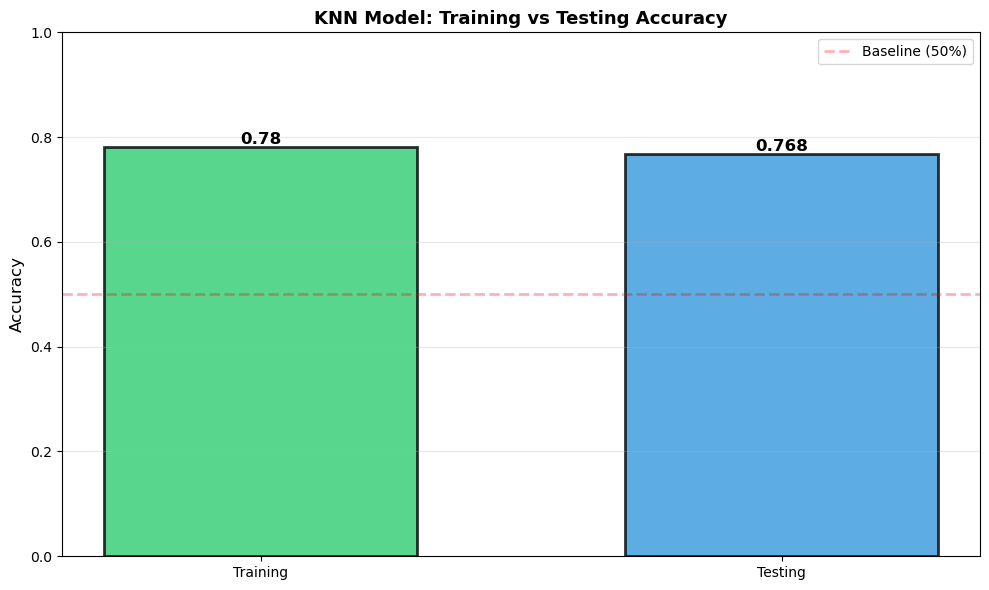


SUMMARY
Total races analyzed: 2260
Training samples: 1808 | Testing samples: 452
Overfitting risk: LOW


In [12]:
# Evaluate Training vs Testing Performance
y_pred_train = knn_model.predict(X_train)
y_pred_test = knn_model.predict(X_test)

train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print("\n" + "="*60)
print("MODEL PERFORMANCE: TRAINING vs TESTING")
print("="*60)
print(f"Training Accuracy: {round(train_accuracy, 3)}")
print(f"Testing Accuracy:  {round(test_accuracy, 3)}")
print(f"Difference:        {round(train_accuracy - test_accuracy, 3)}")

if train_accuracy - test_accuracy > 0.05:
	print("\n  Note: Large difference suggests possible overfitting")
else:
	print("\n Model generalizes well to unseen data")

# Visualize Training vs Testing Accuracy
fig, ax = plt.subplots(figsize=(10, 6))
categories = ['Training', 'Testing']
accuracies = [train_accuracy, test_accuracy]
colors = ['#2ecc71', '#3498db']

bars = ax.bar(categories, accuracies, color=colors, alpha=0.8, edgecolor='black', linewidth=2, width=0.6)

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{round(acc, 3)}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('KNN Model: Training vs Testing Accuracy', fontsize=13, fontweight='bold')
ax.set_ylim([0, 1.0])
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.3, linewidth=2, label='Baseline (50%)')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f"Total races analyzed: {len(model_df)}")
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")
print(f"Overfitting risk: {'LOW' if train_accuracy - test_accuracy <= 0.05 else 'MODERATE'}")


## Interpretation of Results

**KNN:** The model shows similar performance on both training and testing data, which suggests it is learning consistent patterns rather than just fitting to past races. As a classifier, it is able to separate drivers into good and worse performance groups using qualifying, team, and track context. The probability output is then used as a practical way to order drivers within the same race and suggest a Top 3 (clossest to the first in the scale).

## Summary

Overall, the classification results show that the selected feature set provides a workable signal for separating strong and weak race performances. The model’s output distribution makes it possible to compare drivers within the same race context and identify relative performance differences.

These results confirm that a similarity-based classification approach can support a ranking system where drivers are ordered by predicted strength rather than assigned a single fixed outcome.

## Project Evaluation

This project demonstrates how a classification-based model can be used to estimate and rank driver performance using historical race context and pre-race information. The KNN approach allows drivers to be compared to similar past race situations and translated into probability scores that support a Top 3 ranking rather than a single fixed prediction.

The results show that the model is able to capture stable performance patterns related to **qualifying results, team context, and track behavior**, and that these signals are strong enough to separate drivers into good and worse performance groups across different races.


### Strengths

**Explainable Prediction Logic**
The similarity-based nature of KNN makes the model’s behavior easier to understand. Each driver’s probability score is influenced by how closely their current race context matches past races, which helps explain why certain drivers are ranked higher than others.

**Use of Meaningful Performance Features**
The model relies on features that were supported by the exploratory analysis, such as qualifying performance, constructor context, and track identity. This creates a clear link between the data patterns observed in EDA and the way the model makes its predictions.

**Structured and Consistent Input Handling**
By enforcing clear feature formats and consistent data preprocessing, the model reduces the impact of small input inconsistencies. This helps maintain stable predictions across different race scenarios and keeps the classification process reliable.


### Limitations and Challenges

**Limited Awareness of Real-Time Race Factors**
The model is built around historical and pre-race information. Factors such as car upgrades during the season, changing weather conditions, penalties, race strategies, and unexpected incidents like crashes are not directly represented. These elements can strongly influence race outcomes and introduce uncertainty that the model cannot currently capture.

**Top 10-Based Performance Labeling**
By defining performance as a binary Top 10 outcome, the model simplifies the grid into two groups. While this makes the classification task manageable, it also limits the model’s ability to reflect cases where drivers starting further back still achieve podium finishes or strong results.

**Scalability and Complexity Handling**
As more data and features are added, the distance-based nature of KNN becomes less efficient and less capable of capturing complex interactions between variables such as team, car development, and track-specific performance trends.


### Real-World Potential

In a practical context, this model could be used as a **support tool** to explore likely strong performers before a race rather than as a definitive prediction system. The probability-based ranking allows users to compare drivers within the same race context and examine different performance scenarios based on qualifying and track conditions.

At the same time, real races remain highly dynamic. Human decision-making, live strategy changes, and unpredictable events play a major role in final outcomes, which means the model is best used to guide interpretation rather than replace expert judgment.


### Next Steps and Future Improvements

* **Broader Context Integration**
Including additional variables such as weather conditions, penalty history, or indicators of recent car upgrades could help the model better adapt to changing race environments.

* **Full Grid Modeling**
Extending the classification beyond a Top 10 focus would allow the model to better represent the entire field and capture cases where lower-grid drivers move into strong finishing positions.

* **Alternative Classification Models**
Testing models designed for probability-based prediction, such as CatBoost or LightGBM, could help capture more complex feature interactions and potentially improve accuracy.

* **Race-Based Evaluation Strategy**
Evaluating the model using full races as test cases, rather than random data splits, would provide a more realistic measure of how well it performs on unseen events.



## Final Reflection

This project followed a **data-first approach**, where the main challenge was understanding the dataset and shaping a clear prediction goal before even thinking about the model. Cleaning the data, working with time-based values, and handling categorical features showed how much the final results depend on how well the data is prepared.

Later in the process, I chose to work with **KNN classification** to see how a similarity-based method could be turned into a probability-driven ranking system. The results remain consistent between training and testing, which suggests the model is picking up general performance patterns rather than just repeating past race outcomes.

From a technical point of view, this project helped me better understand **feature encoding, scaling, and model evaluation**, and how classification outputs can be used in a more practical way to rank drivers instead of only labeling them.